# 1 EDA

### 1.1 Imports and Setup

In [5]:
import os
import json
import glob
import random
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

possible_roots = [
    "/kaggle/input",
    "/kaggle/input/competitions"
]

DATA_ROOT = None
for base in possible_roots:
    if not os.path.exists(base):
        continue
    for d in os.listdir(base):
        candidate = os.path.join(base, d)
        if os.path.isdir(candidate):
            train_json = os.path.join(candidate, "train", "annotations_coco.json")
            if os.path.exists(train_json):
                DATA_ROOT = candidate
                break
    if DATA_ROOT:
        break

if DATA_ROOT is None:
    raise FileNotFoundError("Could not find the competition data. Make sure the competition is added to your notebook.")

print("✅ Using DATA_ROOT =", DATA_ROOT)

TRAIN_DIR = os.path.join(DATA_ROOT, "train")
VAL_DIR   = os.path.join(DATA_ROOT, "val")
TEST_CSV  = os.path.join(DATA_ROOT, "test_images.csv")

print("Train exists:", os.path.exists(TRAIN_DIR))
print("Val exists:  ", os.path.exists(VAL_DIR))
print("Test CSV:    ", os.path.exists(TEST_CSV))

sample_clip = os.listdir(os.path.join(TRAIN_DIR, "images"))[0]
sample_img = os.listdir(os.path.join(TRAIN_DIR, "images", sample_clip))[0]
print("Sample image path:", os.path.join(TRAIN_DIR, "images", sample_clip, sample_img))

✅ Using DATA_ROOT = /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026
Train exists: True
Val exists:   True
Test CSV:     True
Sample image path: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026/train/images/uav0000361_02323_v/0000212.jpg


### 1.2 Load COCO Annotations

In [6]:
with open(os.path.join(TRAIN_DIR, "annotations_coco.json"), "r") as f:
    train_coco = json.load(f)

with open(os.path.join(VAL_DIR, "annotations_coco.json"), "r") as f:
    val_coco = json.load(f)

print("Train images:", len(train_coco["images"]))
print("Train annotations:", len(train_coco["annotations"]))
print("Train categories:", train_coco["categories"])
print("Val images:", len(val_coco["images"]))
print("Val annotations:", len(val_coco["annotations"]))

Train images: 24201
Train annotations: 1616260
Train categories: [{'id': 1, 'name': 'person'}, {'id': 2, 'name': 'bicycle'}, {'id': 3, 'name': 'car'}, {'id': 4, 'name': 'van'}, {'id': 5, 'name': 'truck'}, {'id': 6, 'name': 'tricycle'}, {'id': 7, 'name': 'bus'}, {'id': 8, 'name': 'motor'}]
Val images: 2846
Val annotations: 146092


### 1.3 Class Distribution

Category map: {1: 'person', 2: 'bicycle', 3: 'car', 4: 'van', 5: 'truck', 6: 'tricycle', 7: 'bus', 8: 'motor'}


/tmp/ipykernel_49/2115043423.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_names, y=class_values, palette="viridis")


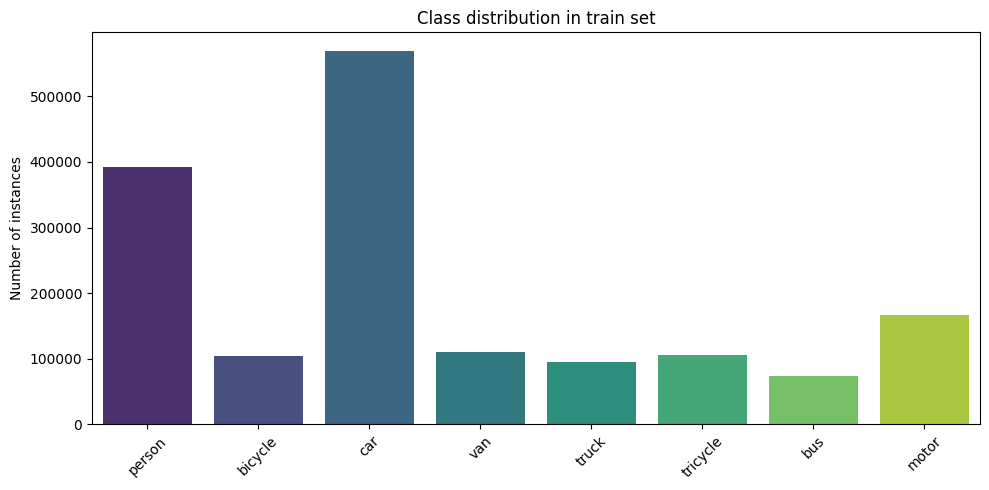

      class   count  percentage
0    person  392544       24.29
1   bicycle  104098        6.44
2       car  569144       35.21
3       van  110783        6.85
4     truck   94341        5.84
5  tricycle  105192        6.51
6       bus   73496        4.55
7     motor  166662       10.31


In [7]:
cat_id_to_name = {c["id"]: c["name"] for c in train_coco["categories"]}
print("Category map:", cat_id_to_name)

class_counts = Counter([ann["category_id"] for ann in train_coco["annotations"]])
class_names  = [cat_id_to_name[cid] for cid in sorted(class_counts.keys())]
class_values = [class_counts[cid] for cid in sorted(class_counts.keys())]

plt.figure(figsize=(10, 5))
sns.barplot(x=class_names, y=class_values, palette="viridis")
plt.title("Class distribution in train set")
plt.ylabel("Number of instances")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

df_classes = pd.DataFrame({"class": class_names, "count": class_values})
df_classes["percentage"] = (df_classes["count"] / df_classes["count"].sum() * 100).round(2)
print(df_classes)

**Severe Class Imbalance**: The dataset is dominated by `car` (35.2%) and `person` (24.3%) classes. In contrast, classes like `bus` (4.5%), `truck` (5.8%), and `bicycle` (6.4%) are underrepresented. 
   * *Implication*: We will need to use techniques such as Focal Loss, class-weighted sampling, or Copy-Paste augmentation to prevent the model from ignoring rare classes.

### 1.4 Object Size Distribution (COCO categories)

Small  (<32x32): 275347  (24.91%)
Medium (<96x96): 702004 (63.50%)
Large  (>=96x96): 128165  (11.59%)


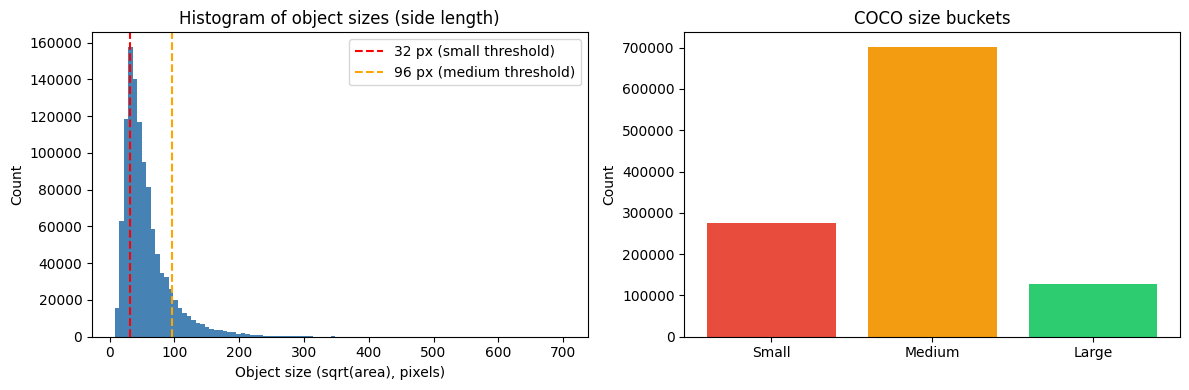

In [8]:
areas = [ann["area"] for ann in train_coco["annotations"] if ann.get("iscrowd", 0) == 0]
areas = np.array(areas)

small  = np.sum(areas < 32**2)
medium = np.sum((areas >= 32**2) & (areas < 96**2))
large  = np.sum(areas >= 96**2)
total  = len(areas)

print(f"Small  (<32x32): {small}  ({small/total*100:.2f}%)")
print(f"Medium (<96x96): {medium} ({medium/total*100:.2f}%)")
print(f"Large  (>=96x96): {large}  ({large/total*100:.2f}%)")

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.hist(np.sqrt(areas), bins=100, color="steelblue")
plt.xlabel("Object size (sqrt(area), pixels)")
plt.ylabel("Count")
plt.title("Histogram of object sizes (side length)")
plt.axvline(32, color="red",    linestyle="--", label="32 px (small threshold)")
plt.axvline(96, color="orange", linestyle="--", label="96 px (medium threshold)")
plt.legend()

plt.subplot(1, 2, 2)
plt.bar(["Small", "Medium", "Large"], [small, medium, large], color=["#e74c3c","#f39c12","#2ecc71"])
plt.title("COCO size buckets")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

**Object Scale Distribution**: The size histogram reveals a large peak around 30-50 pixels. According to COCO thresholds, 63.5% of objects are Medium (32-96px) and 24.9% are Small (<32px). 
   * *Implication*: Training at a standard 640x640 resolution will destroy the features of small objects. We must train at a higher resolution (e.g., 1024x1024 or 1280x1280) and strongly consider using SAHI (Slicing Aided Hyper Inference) during inference.

### 1.5 Objects Per Frame (Density)

Mean objects per frame: 66.78
Median: 54.0
Max: 342
Frames with 0 objects: 3


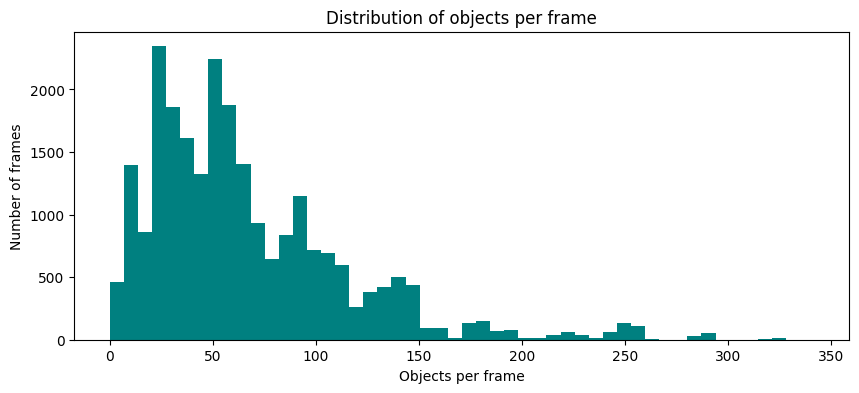

In [9]:
per_image = defaultdict(int)
for ann in train_coco["annotations"]:
    per_image[ann["image_id"]] += 1

counts_per_image = np.array([per_image.get(img["id"], 0) for img in train_coco["images"]])

print("Mean objects per frame:", counts_per_image.mean().round(2))
print("Median:", np.median(counts_per_image))
print("Max:", counts_per_image.max())
print("Frames with 0 objects:", int((counts_per_image == 0).sum()))

plt.figure(figsize=(10, 4))
plt.hist(counts_per_image, bins=50, color="teal")
plt.xlabel("Objects per frame")
plt.ylabel("Number of frames")
plt.title("Distribution of objects per frame")
plt.show()

**High Scene Density**: On average, there are 66.8 objects per frame, with a maximum of 342 objects in a single frame.
   * *Implication*: Standard Non-Maximum Suppression (NMS) might suppress valid neighboring boxes in such crowded scenes. We should experiment with Soft-NMS. For query-based models (like RT-DETR), we must ensure the number of queries is large enough (e.g., >300) to cover the maximum density.

### 1.6 Variation Across Clips

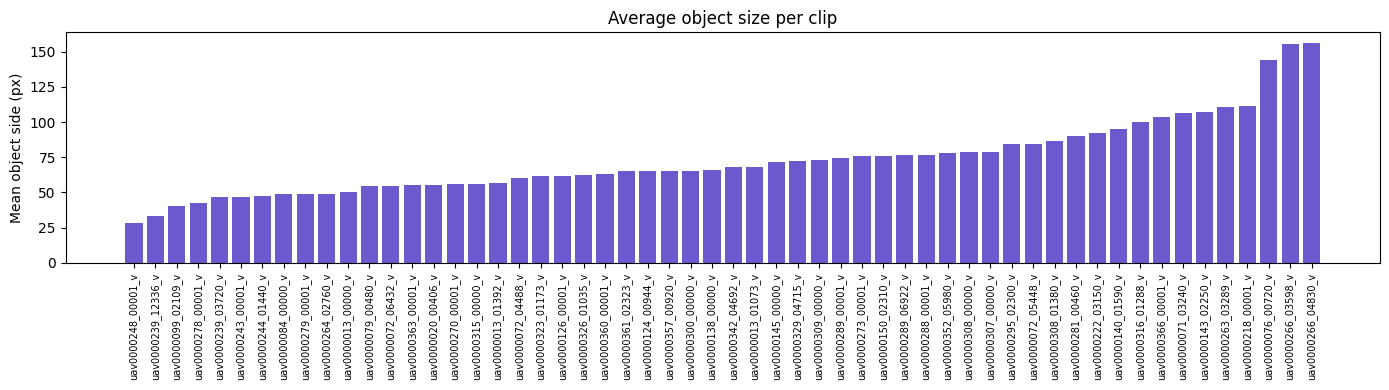

       mean_side_px     n_objects
count     56.000000     56.000000
mean      73.297546  19741.357143
std       27.068001  16073.296195
min       28.516727    706.000000
25%       55.317156   8518.500000
50%       67.154547  16044.500000
75%       84.271855  25812.250000
max      156.017841  64916.000000


In [10]:
img_id_to_clip = {}
for img in train_coco["images"]:
    clip = img.get("video") or img["file_name"].split("/")[-2]
    img_id_to_clip[img["id"]] = clip

clip_to_sizes = defaultdict(list)
for ann in train_coco["annotations"]:
    if ann.get("iscrowd", 0) == 0:
        clip = img_id_to_clip[ann["image_id"]]
        clip_to_sizes[clip].append(ann["area"])

clip_stats = pd.DataFrame([
    {"clip": c, "mean_side_px": np.sqrt(np.mean(v)), "n_objects": len(v)}
    for c, v in clip_to_sizes.items()
]).sort_values("mean_side_px")

plt.figure(figsize=(14, 4))
plt.bar(range(len(clip_stats)), clip_stats["mean_side_px"], color="slateblue")
plt.xticks(range(len(clip_stats)), clip_stats["clip"], rotation=90, fontsize=7)
plt.ylabel("Mean object side (px)")
plt.title("Average object size per clip")
plt.tight_layout()
plt.show()

print(clip_stats.describe())

**High Intra-Clip Variance**: The average object size varies drastically across different video clips (ranging from 28px to 156px), representing different camera altitudes and scene types (highways vs. fields).
   * *Implication*: This confirms that we **must** split our validation set by video clip (GroupKFold) to avoid data leakage. Furthermore, we must use aggressive scale augmentation during training to make the model robust to these variations.

### 1.7 Ground-Truth Visualization

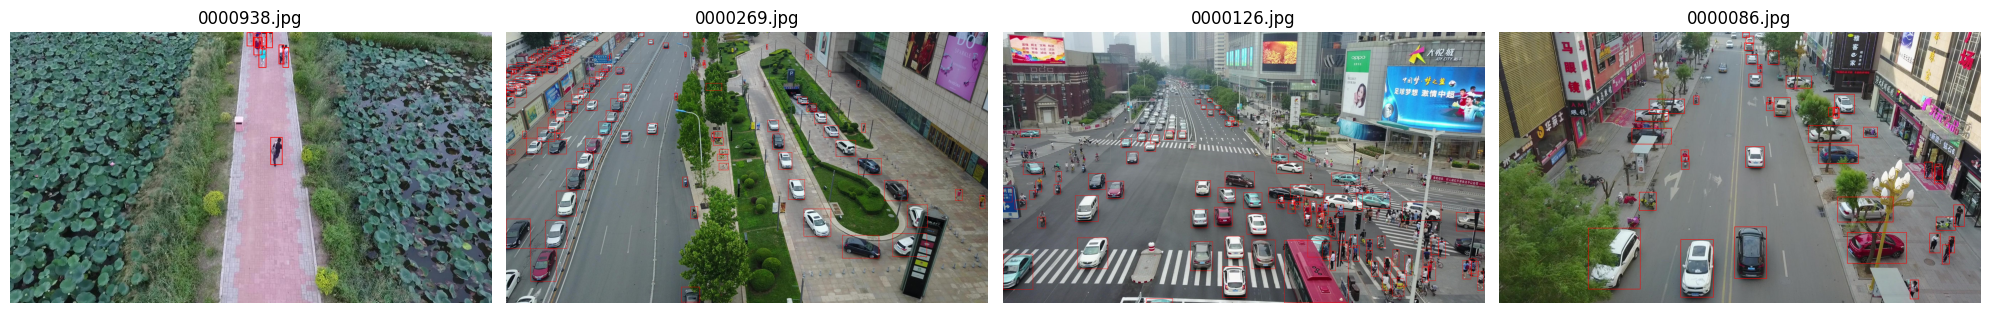

In [11]:
from PIL import Image, ImageDraw

def visualize_gt(coco, root, n=4, seed=28):
    random.seed(seed)
    img_entries = random.sample(coco["images"], n)
    fig, axes = plt.subplots(1, n, figsize=(5*n, 5))
    if n == 1: axes = [axes]

    anns_by_img = defaultdict(list)
    for ann in coco["annotations"]:
        anns_by_img[ann["image_id"]].append(ann)

    for ax, img_info in zip(axes, img_entries):
        img_path = os.path.join(root, img_info["file_name"])
        image = Image.open(img_path).convert("RGB")
        draw = ImageDraw.Draw(image)
        for ann in anns_by_img[img_info["id"]]:
            x, y, w, h = ann["bbox"]
            color = "red" if ann.get("iscrowd", 0) == 0 else "gray"
            draw.rectangle([x, y, x + w, y + h], outline=color, width=2)
        ax.imshow(image)
        ax.axis("off")
        ax.set_title(img_info["file_name"].split("/")[-1])
    plt.tight_layout()
    plt.show()

visualize_gt(train_coco, TRAIN_DIR, n=4)

### 1.8 Anchor Analysis via K-Means (for RetinaNet)

Recommended anchor (w, h) from your data:
  w=23.8, h=33.7   aspect_ratio=0.71
  w=52.2, h=39.3   aspect_ratio=1.33
  w=40.1, h=70.5   aspect_ratio=0.57
  w=87.8, h=52.2   aspect_ratio=1.68
  w=84.7, h=106.5   aspect_ratio=0.80
  w=145.9, h=72.8   aspect_ratio=2.00
  w=225.3, h=111.8   aspect_ratio=2.02
  w=158.3, h=173.7   aspect_ratio=0.91
  w=336.4, h=221.7   aspect_ratio=1.52


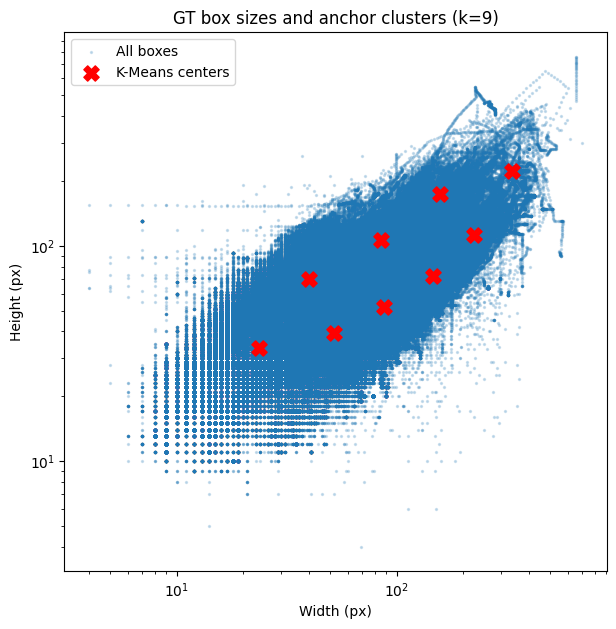

In [12]:
from sklearn.cluster import KMeans

wh = np.array([[ann["bbox"][2], ann["bbox"][3]]
               for ann in train_coco["annotations"] if ann.get("iscrowd", 0) == 0])

k = 9
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10).fit(wh)
centers = kmeans.cluster_centers_
centers = centers[np.argsort(centers[:, 0] * centers[:, 1])]  # sort by area

print("Recommended anchor (w, h) from your data:")
for c in centers:
    print(f"  w={c[0]:.1f}, h={c[1]:.1f}   aspect_ratio={c[0]/c[1]:.2f}")

plt.figure(figsize=(7, 7))
plt.scatter(wh[:, 0], wh[:, 1], s=2, alpha=0.2, label="All boxes")
plt.scatter(centers[:, 0], centers[:, 1], c="red", s=120, marker="X", label="K-Means centers")
plt.xlabel("Width (px)"); plt.ylabel("Height (px)")
plt.title("GT box sizes and anchor clusters (k=9)")
plt.xscale("log"); plt.yscale("log")
plt.legend()
plt.show()

**Custom Anchor Configuration**: K-Means clustering (k=9) on the ground-truth bounding boxes produced highly specific anchor sizes (e.g., 23.8x33.7, 52.2x39.3, 145.9x72.8), which are significantly smaller than the default COCO anchors.
   * *Implication*: We will use these exact dimensions to configure the anchors for our anchor-based models (RetinaNet and Faster R-CNN) to maximize their matching rate with ground-truth objects.

###  1.9 Image Resolution Analysis

           image_id                         file_name      clip  frame  width  \
0  clip_001_0000001  test/images/clip_001/0000001.jpg  clip_001      1   1920   
1  clip_001_0000002  test/images/clip_001/0000002.jpg  clip_001      2   1920   
2  clip_001_0000003  test/images/clip_001/0000003.jpg  clip_001      3   1920   
3  clip_001_0000004  test/images/clip_001/0000004.jpg  clip_001      4   1920   
4  clip_001_0000005  test/images/clip_001/0000005.jpg  clip_001      5   1920   

   height  
0    1080  
1    1080  
2    1080  
3    1080  
4    1080  

Columns: ['image_id', 'file_name', 'clip', 'frame', 'width', 'height']


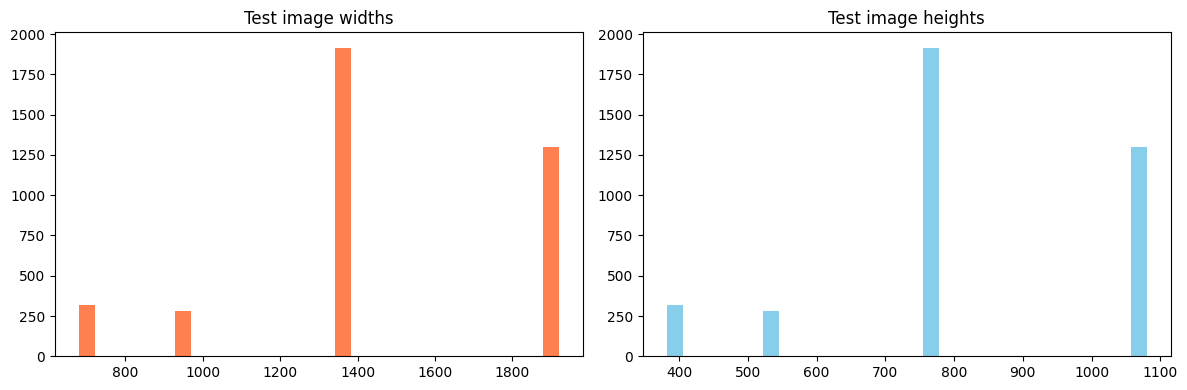


Test clips: 48
Total test frames: 3811
Resolution combinations:
width  height
1360   764       1474
1920   1080       991
1344   756        441
680    382        321
1904   1072       305
dtype: int64


In [13]:
test_df = pd.read_csv(TEST_CSV)
print(test_df.head())
print("\nColumns:", test_df.columns.tolist())

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.hist(test_df["width"], bins=30, color="coral")
plt.title("Test image widths")
plt.subplot(1, 2, 2)
plt.hist(test_df["height"], bins=30, color="skyblue")
plt.title("Test image heights")
plt.tight_layout()
plt.show()

print("\nTest clips:", test_df["clip"].nunique())
print("Total test frames:", len(test_df))
print("Resolution combinations:")
print(test_df.groupby(["width", "height"]).size().sort_values(ascending=False).head())

**Variable Test Resolutions**: Test images come in 4 distinct resolutions, with the majority being 1920x1080 and 1360x764.
   * *Implication*: The inference pipeline must properly resize inputs using letterboxing and accurately scale the predicted bounding boxes back to the original pixel coordinates before writing the `submission.csv`.

### 1.10 Create and Save the Validation Split (by CLIP, not frame)

In [14]:
# Get unique clips in the TRAIN set
train_clips = sorted({img["file_name"].split("/")[-2] for img in train_coco["images"]})
print(f"Total train clips: {len(train_clips)}")
print(train_clips[:5])

random.seed(28)
random.shuffle(train_clips)
n_val = max(1, int(0.2 * len(train_clips)))
val_clips   = set(train_clips[:n_val])
train_clips = set(train_clips[n_val:])

print("Train clips:", len(train_clips))
print("Val clips:  ", len(val_clips))
print("Overlap:", train_clips & val_clips)  # Must be empty

# Save lists for later use by all 4 experiments
OUT_DIR = "/kaggle/working/splits"
os.makedirs(OUT_DIR, exist_ok=True)
with open(os.path.join(OUT_DIR, "train_clips.txt"), "w") as f:
    f.write("\n".join(sorted(train_clips)))
with open(os.path.join(OUT_DIR, "val_clips.txt"), "w") as f:
    f.write("\n".join(sorted(val_clips)))
print("Saved splits to", OUT_DIR)

Total train clips: 56
['uav0000013_00000_v', 'uav0000013_01073_v', 'uav0000013_01392_v', 'uav0000020_00406_v', 'uav0000071_03240_v']
Train clips: 45
Val clips:   11
Overlap: set()
Saved splits to /kaggle/working/splits


### 1.11 Summary

In [15]:
print(f"""
=== EDA SUMMARY ===

1. Class imbalance:
   - Most common class: {class_names[int(np.argmax(class_values))]} ({max(class_values)} instances)
   - Rarest class:      {class_names[int(np.argmin(class_values))]} ({min(class_values)} instances)

2. Object sizes:
   - Small objects (<32px):  {small/total*100:.1f}%
   - Medium objects:         {medium/total*100:.1f}%
   - Large objects:          {large/total*100:.1f}%
   => Training at 1280x1280 + SAHI at inference recommended.

3. Density:
   - Mean objects per frame: {counts_per_image.mean():.1f}
   - Max objects per frame:  {counts_per_image.max()}

4. Recommended anchors (K-Means k=9) — see Cell 8 printout.

5. Validation split:
   - {len(train_clips)} train clips, {len(val_clips)} val clips (GroupKFold by clip).
""")


=== EDA SUMMARY ===

1. Class imbalance:
   - Most common class: car (569144 instances)
   - Rarest class:      bus (73496 instances)

2. Object sizes:
   - Small objects (<32px):  24.9%
   - Medium objects:         63.5%
   - Large objects:          11.6%
   => Training at 1280x1280 + SAHI at inference recommended.

3. Density:
   - Mean objects per frame: 66.8
   - Max objects per frame:  342

4. Recommended anchors (K-Means k=9) — see Cell 8 printout.

5. Validation split:
   - 45 train clips, 11 val clips (GroupKFold by clip).



# Preprocessing & Input Resolution Strategy

 ### 2.1 Setup

In [16]:
import os, json, random, time
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

SEED = 28
random.seed(SEED)
np.random.seed(SEED)

WORK_DIR = Path("/kaggle/working")
CKPT_DIR = WORK_DIR / "checkpoints"
SPLITS_DIR = WORK_DIR / "splits"
CKPT_DIR.mkdir(parents=True, exist_ok=True)
SPLITS_DIR.mkdir(parents=True, exist_ok=True)

print("DATA_ROOT:", DATA_ROOT)
print("WORK_DIR:", WORK_DIR)

DATA_ROOT: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026
WORK_DIR: /kaggle/working


### 2.2 Clip-level split

In [17]:
train_clips = sorted({p.name for p in (Path(TRAIN_DIR) / "images").iterdir() if p.is_dir()})
val_clips   = sorted({p.name for p in (Path(VAL_DIR)   / "images").iterdir() if p.is_dir()})

assert set(train_clips).isdisjoint(set(val_clips)), "train/ and val/ clips overlap"

(SPLITS_DIR / "train_clips.txt").write_text("\n".join(train_clips))
(SPLITS_DIR / "val_clips.txt").write_text("\n".join(val_clips))

print("Train clips:", len(train_clips))
print("Val clips:  ", len(val_clips))
print("Overlap:", set(train_clips) & set(val_clips))

Train clips: 56
Val clips:   7
Overlap: set()


Train and validation clips come from separate official folders, and the overlap check confirms that no clip appears in both sets.
   * *Implication*: Frames within one clip are highly correlated, so this split rules out temporal leakage and the validation metrics reflect generalization to unseen scenes. We keep the official split for all experiments instead of any frame-level sampling.

### 2.3 Dataset indexing

In [18]:
def index_split(split_dir: Path):
    rows = []
    for img_path in sorted((split_dir / "images").rglob("*.jpg")):
        clip = img_path.parent.name
        frame = img_path.stem
        rows.append({
            "clip": clip,
            "frame": frame,
            "image_path": str(img_path),
            "label_path": str(split_dir / "labels" / clip / f"{frame}.txt"),
            "ignore_path": str(split_dir / "ignore" / clip / f"{frame}.txt"),
        })
    return pd.DataFrame(rows)

train_index = index_split(Path(TRAIN_DIR))
val_index   = index_split(Path(VAL_DIR))

assert len(val_index) > 0, "val_index is empty — check paths"

print("Train frames:", len(train_index))
print("Val frames:  ", len(val_index))
val_index.head()

Train frames: 24201
Val frames:   2846


,clip,frame,image_path,label_path,ignore_path
0,uav0000086_00000_v,0000001,/kaggle/input/competitions/multiple-object-vid...,/kaggle/input/competitions/multiple-object-vid...,/kaggle/input/competitions/multiple-object-vid...
1,uav0000086_00000_v,0000002,/kaggle/input/competitions/multiple-object-vid...,/kaggle/input/competitions/multiple-object-vid...,/kaggle/input/competitions/multiple-object-vid...
2,uav0000086_00000_v,0000003,/kaggle/input/competitions/multiple-object-vid...,/kaggle/input/competitions/multiple-object-vid...,/kaggle/input/competitions/multiple-object-vid...
3,uav0000086_00000_v,0000004,/kaggle/input/competitions/multiple-object-vid...,/kaggle/input/competitions/multiple-object-vid...,/kaggle/input/competitions/multiple-object-vid...
4,uav0000086_00000_v,0000005,/kaggle/input/competitions/multiple-object-vid...,/kaggle/input/competitions/multiple-object-vid...,/kaggle/input/competitions/multiple-object-vid...


The index contains 24,201 training frames and 2,846 validation frames (about 10.5% of all labeled frames). Every frame has a YOLO-format label file and a separate ignore-region file.
   * *Implication*: The validation set is relatively small, so metrics computed on it can be noisy. Ignore regions must be taken into account during evaluation and training so that detections inside them are not counted as false positives.

### 2.4 Image size statistics per clip

In [19]:
def read_image_sizes(df_index: pd.DataFrame) -> pd.DataFrame:
    sizes = []
    for p in tqdm(df_index["image_path"], desc="reading sizes"):
        img = cv2.imread(p, cv2.IMREAD_UNCHANGED)
        sizes.append((img.shape[1], img.shape[0]))
    df = df_index.copy()
    df["width"], df["height"] = zip(*sizes)
    return df

val_index = read_image_sizes(val_index)
val_index.groupby("clip")[["width", "height"]].agg(["min", "max", "mean"])

reading sizes:   0%|          | 0/2846 [00:00<?, ?it/s]

width               height              
                     min   max    mean    min   max    mean
clip                                                       
uav0000086_00000_v  1344  1344  1344.0    756   756   756.0
uav0000117_02622_v  2720  2720  2720.0   1530  1530  1530.0
uav0000137_00458_v  2688  2688  2688.0   1512  1512  1512.0
uav0000182_00000_v  1344  1344  1344.0    756   756   756.0
uav0000268_05773_v  3840  3840  3840.0   2160  2160  2160.0
uav0000305_00000_v  1904  1904  1904.0   1071  1071  1071.0
uav0000339_00001_v  1904  1904  1904.0   1071  1071  1071.0

The 7 validation clips come in 5 distinct resolutions, from 1344x756 to 3840x2160 (a ~2.9x difference in width). Resolution is constant within each clip, and all frames share the same ~16:9 aspect ratio. These resolutions also differ from the test set (mostly 1920x1080 and 1360x764).
   * *Implication*: There is no single scale factor for the whole dataset, so every frame needs its own scale and padding metadata to map predictions back to original coordinates. The shared aspect ratio means aspect-preserving resizing is straightforward, while a plain square resize would distort every frame by the same factor (~1.78x). The pipeline must not depend on any specific input resolution.

### 2.5 Canvas size selection

In [20]:
sample_train = train_index.sample(min(2000, len(train_index)), random_state=SEED)
train_sizes = []
for p in tqdm(sample_train["image_path"], desc="max size"):
    img = cv2.imread(p, cv2.IMREAD_UNCHANGED)
    train_sizes.append((img.shape[1], img.shape[0]))

max_w = max(s[0] for s in train_sizes)
max_h = max(s[1] for s in train_sizes)
CANVAS_SIZE = (max_w, max_h)

print("Max width :", max_w)
print("Max height:", max_h)
print("CANVAS_SIZE:", CANVAS_SIZE)

max size:   0%|          | 0/2000 [00:00<?, ?it/s]

Max width : 2720
Max height: 1530
CANVAS_SIZE: (2720, 1530)


The maximum size found in a 2,000-frame train sample is 2720x1530, which becomes the canvas for the random-pad strategy. It was estimated from a sample, and the validation set already contains a 3840x2160 clip that does not fit into it. The canvas holds ~4.2M pixels, about 2.5x more than a 1280x1280 input (~1.6M).
   * *Implication*: A canvas derived from a sample is not guaranteed to cover all frames, so oversized images still have to be downscaled. A canvas this large also makes every forward pass considerably more expensive.

### 2.6 Resize strategies — implementations

In [21]:
def letterbox(img, new_size, pad_value=114):
    h, w = img.shape[:2]
    scale = min(new_size / w, new_size / h)
    nw, nh = int(round(w * scale)), int(round(h * scale))
    resized = cv2.resize(img, (nw, nh), interpolation=cv2.INTER_LINEAR)
    canvas = np.full((new_size, new_size, 3), pad_value, dtype=img.dtype)
    top, left = (new_size - nh) // 2, (new_size - nw) // 2
    canvas[top:top + nh, left:left + nw] = resized
    return canvas, dict(scale=scale, pad_x=left, pad_y=top,
                        new_w=nw, new_h=nh, out_w=new_size, out_h=new_size)

def plain_resize(img, new_size):
    h, w = img.shape[:2]
    resized = cv2.resize(img, (new_size, new_size), interpolation=cv2.INTER_LINEAR)
    return resized, dict(scale_x=new_size / w, scale_y=new_size / h,
                         new_w=new_size, new_h=new_size,
                         out_w=new_size, out_h=new_size)

def random_pad_canvas(img, canvas_size, seed_key, pad_value=114):
    h0, w0 = img.shape[:2]
    canvas_w, canvas_h = canvas_size

    if w0 > canvas_w or h0 > canvas_h:
        scale = min(canvas_w / w0, canvas_h / h0)
        new_w, new_h = int(round(w0 * scale)), int(round(h0 * scale))
        img = cv2.resize(img, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
    else:
        scale = 1.0
        new_w, new_h = w0, h0

    rng = random.Random(SEED + int(seed_key))
    max_x = canvas_w - new_w
    max_y = canvas_h - new_h
    pad_x = rng.randint(0, max_x) if max_x > 0 else 0
    pad_y = rng.randint(0, max_y) if max_y > 0 else 0

    canvas = np.full((canvas_h, canvas_w, 3), pad_value, dtype=img.dtype)
    canvas[pad_y:pad_y + new_h, pad_x:pad_x + new_w] = img

    return canvas, dict(scale=scale, pad_x=pad_x, pad_y=pad_y,
                        new_w=new_w, new_h=new_h,
                        out_w=canvas_w, out_h=canvas_h)

def scale_boxes_down(boxes, meta, mode):
    if mode in ("letterbox", "randompad"):
        s, px, py = meta["scale"], meta["pad_x"], meta["pad_y"]
        return np.stack([boxes[:, 0] * s + px, boxes[:, 1] * s + py,
                         boxes[:, 2] * s + px, boxes[:, 3] * s + py], axis=1)
    if mode == "plain":
        return np.stack([boxes[:, 0] * meta["scale_x"], boxes[:, 1] * meta["scale_y"],
                         boxes[:, 2] * meta["scale_x"], boxes[:, 3] * meta["scale_y"]], axis=1)
    raise ValueError(mode)

def boxes_to_original(boxes, meta, mode, orig_w, orig_h):
    if mode in ("letterbox", "randompad"):
        s, px, py = meta["scale"], meta["pad_x"], meta["pad_y"]
        x1 = (boxes[:, 0] - px) / s
        y1 = (boxes[:, 1] - py) / s
        x2 = (boxes[:, 2] - px) / s
        y2 = (boxes[:, 3] - py) / s
    elif mode == "plain":
        x1 = boxes[:, 0] / meta["scale_x"]
        y1 = boxes[:, 1] / meta["scale_y"]
        x2 = boxes[:, 2] / meta["scale_x"]
        y2 = boxes[:, 3] / meta["scale_y"]
    else:
        raise ValueError(mode)
    return np.stack([x1, y1, x2, y2], axis=1).clip(0, [orig_w, orig_h, orig_w, orig_h])

### 2.7 YOLO ↔ pixel box conversion

In [22]:
def load_yolo_labels(label_path, img_w, img_h):
    if not os.path.exists(label_path) or os.path.getsize(label_path) == 0:
        return np.zeros((0, 4), dtype=np.float32), np.zeros((0,), dtype=np.int64)
    rows = np.loadtxt(label_path, ndmin=2)
    cls = rows[:, 0].astype(np.int64)
    cx, cy, w, h = rows[:, 1], rows[:, 2], rows[:, 3], rows[:, 4]
    x1 = (cx - w / 2) * img_w
    y1 = (cy - h / 2) * img_h
    x2 = (cx + w / 2) * img_w
    y2 = (cy + h / 2) * img_h
    return np.stack([x1, y1, x2, y2], axis=1), cls

### 2.8 GT visualization sanity check

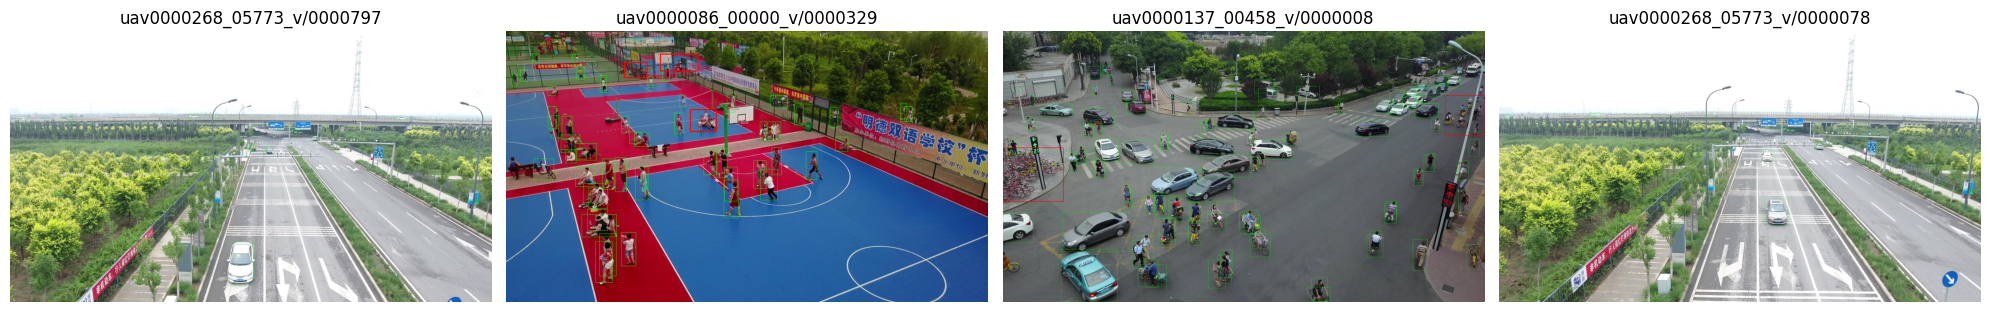

In [23]:
def visualize_yolo_gt(df_index, n=4, show_ignore=True):
    sample = df_index.sample(n, random_state=SEED)
    fig, axes = plt.subplots(1, n, figsize=(5 * n, 5))
    if n == 1:
        axes = [axes]
    for ax, (_, row) in zip(axes, sample.iterrows()):
        img = cv2.cvtColor(cv2.imread(row["image_path"]), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        boxes, _ = load_yolo_labels(row["label_path"], w, h)
        for x1, y1, x2, y2 in boxes:
            cv2.rectangle(img, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 1)
        if show_ignore and os.path.exists(row["ignore_path"]) and os.path.getsize(row["ignore_path"]) > 0:
            ign = np.loadtxt(row["ignore_path"], ndmin=2)
            for cx, cy, bw, bh in ign[:, :4]:
                x1 = int((cx - bw / 2) * w); y1 = int((cy - bh / 2) * h)
                x2 = int((cx + bw / 2) * w); y2 = int((cy + bh / 2) * h)
                cv2.rectangle(img, (x1, y1), (x2, y2), (255, 0, 0), 2)
        ax.imshow(img)
        ax.set_title(f'{row["clip"]}/{row["frame"]}')
        ax.axis("off")
    plt.tight_layout()
    plt.show()

visualize_yolo_gt(val_index, n=4, show_ignore=True)

After converting YOLO-normalized boxes (cx, cy, w, h) to pixel coordinates, the ground-truth boxes (green) align with the objects in the frames, and the ignore regions (red) are drawn separately.
   * *Implication*: The label parsing is correct and can be safely reused for training, evaluation, and for scaling boxes through the resize strategies.

### 2.9 Preprocessing strategy demo

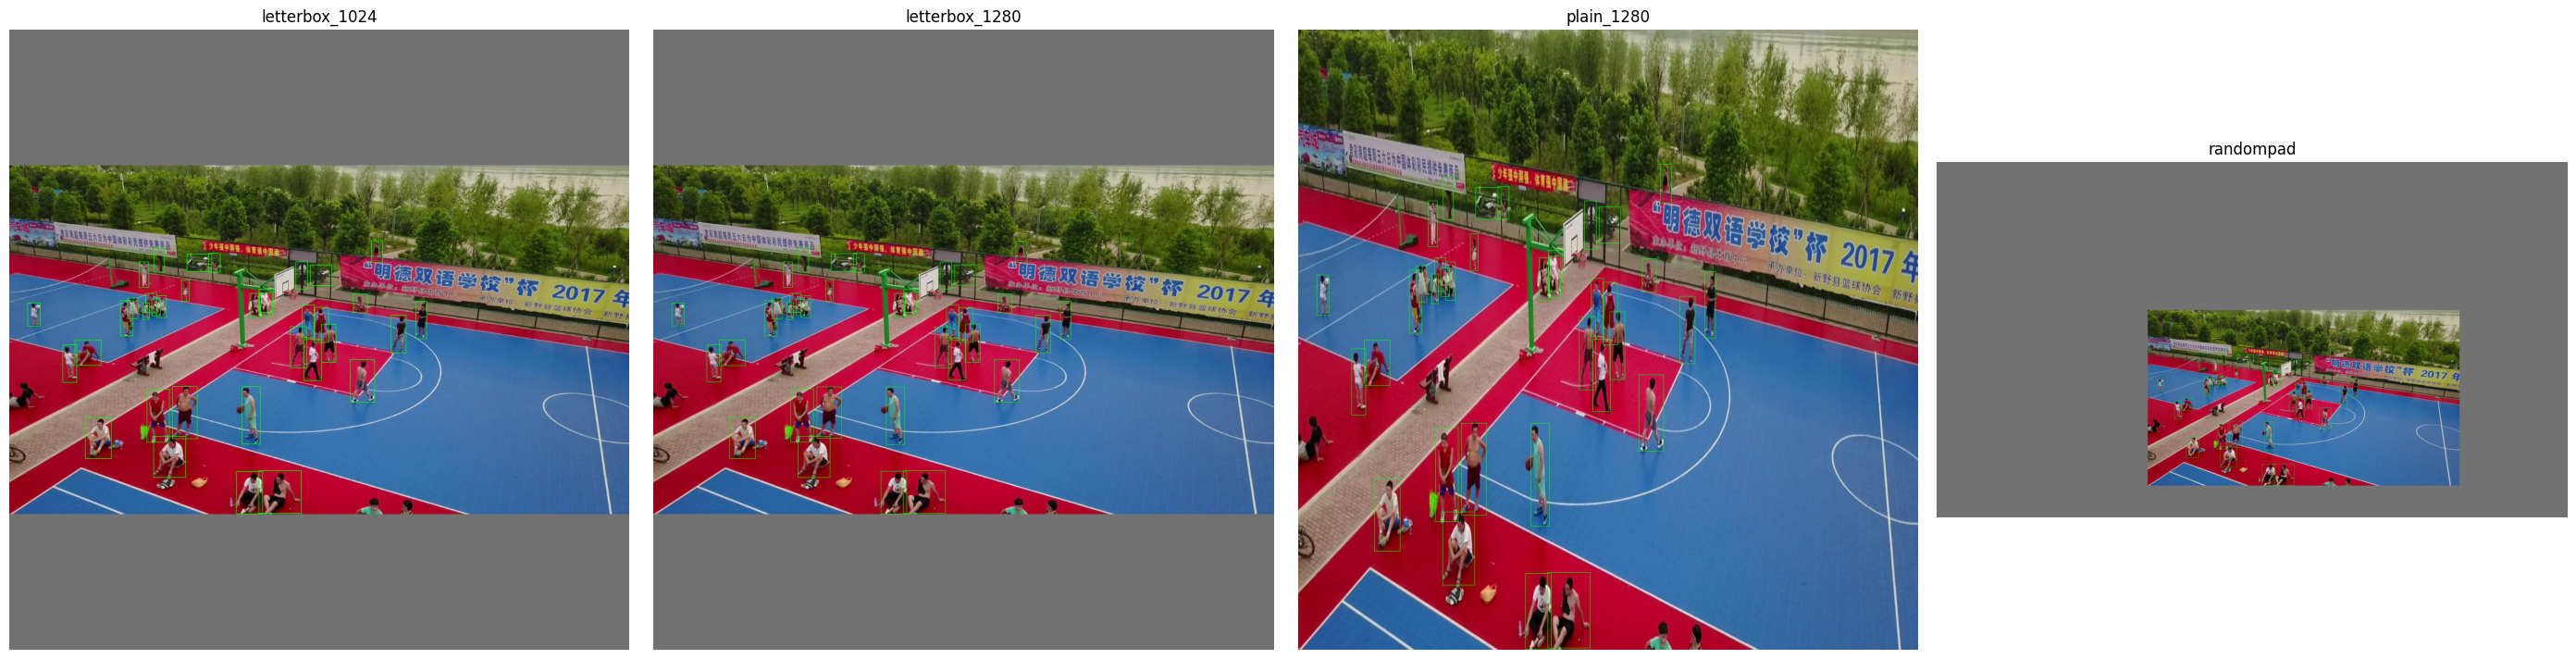

In [24]:
def apply_strategy(img, strategy, size, seed_key):
    if strategy == "letterbox":
        return letterbox(img, size)
    if strategy == "plain":
        return plain_resize(img, size)
    if strategy == "randompad":
        return random_pad_canvas(img, size, seed_key=seed_key)
    raise ValueError(strategy)

demo_row = val_index.iloc[0]
demo_img = cv2.cvtColor(cv2.imread(demo_row["image_path"]), cv2.COLOR_BGR2RGB)
h0, w0 = demo_img.shape[:2]
demo_boxes, _ = load_yolo_labels(demo_row["label_path"], w0, h0)

variants = {
    "letterbox_1024": ("letterbox", 1024),
    "letterbox_1280": ("letterbox", 1280),
    "plain_1280":     ("plain", 1280),
    "randompad":      ("randompad", CANVAS_SIZE),
}

fig, axes = plt.subplots(1, len(variants), figsize=(7 * len(variants), 7))
for ax, (name, (strat, sz)) in zip(axes, variants.items()):
    out, meta = apply_strategy(demo_img, strat, sz, seed_key=hash(demo_row["image_path"]) % 100000)
    scaled = scale_boxes_down(demo_boxes, meta, strat)
    vis = out.copy()
    for x1, y1, x2, y2 in scaled:
        cv2.rectangle(vis, (int(x1), int(y1)), (int(x2), int(y2)), (0, 255, 0), 1)
    ax.imshow(vis)
    ax.set_title(name)
    ax.axis("off")
plt.tight_layout()
plt.show()

Letterbox preserves aspect ratio, but because the frames are 16:9, about 44% of the square input is gray padding. Plain resize uses the full square but stretches objects (the width is squeezed ~1.78x relative to the height). Random-pad keeps the native object scale, but a 1344x756 frame occupies only ~24% of the 2720x1530 canvas. In all variants the boxes stay aligned with the objects after the transform.
   * *Implication*: Plain resize is the main risk for accuracy because it changes object shapes, while random-pad is the main risk for compute because most of its canvas is empty. Both need to be checked quantitatively rather than judged visually.

### 2.10 Pretrained detector

In [28]:
import torch
from torchvision.models.detection import fasterrcnn_resnet50_fpn_v2
from torchvision.transforms import functional as TF
from pathlib import Path

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

weight_path = Path("/kaggle/input/datasets/suchok/my-dataset/fasterrcnn_resnet50_fpn_v2_coco-dd69338a.pth")

print("Weights found:", weight_path.exists())

if weight_path.exists():
    state_dict = torch.load(weight_path, map_location="cpu")
    detector = fasterrcnn_resnet50_fpn_v2(weights=None).to(DEVICE)
    detector.load_state_dict(state_dict)
    detector.eval()
    print("Detector on:", DEVICE)
else:
    print("error")

Weights found: True
Detector on: cuda


### 2.11 Inference wrapper

In [29]:
@torch.no_grad()
def run_detector(image_rgb: np.ndarray, score_thr: float = 0.001):
    tensor = TF.to_tensor(image_rgb)
    tensor = TF.normalize(tensor, mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    out = detector([tensor.to(DEVICE)])[0]
    keep = out["scores"] >= score_thr
    return (out["boxes"][keep].cpu().numpy(),
            out["labels"][keep].cpu().numpy(),
            out["scores"][keep].cpu().numpy())

def predict_with_strategy(image_path, strategy, size):
    img = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    h0, w0 = img.shape[:2]

    seed_key = hash(image_path) % 100000
    inp, meta = apply_strategy(img, strategy, size, seed_key=seed_key)

    t0 = time.time()
    boxes, labels, scores = run_detector(inp)
    dt = time.time() - t0

    boxes_orig = boxes_to_original(boxes, meta, strategy, w0, h0)
    return boxes_orig, labels, scores, dt, meta

### 2.12 Evaluation loop per strategy

In [30]:
STRATEGIES = [
    ("letterbox", 1024),
    ("letterbox", 1280),
    ("plain",     1280),
    ("randompad", CANVAS_SIZE),
]

RANDOMPAD_STATS = {"resized": 0, "as_is": 0}

def evaluate_strategy(strategy, size, df_index, max_frames=None):
    frames = df_index if max_frames is None else df_index.sample(max_frames, random_state=SEED)
    per_frame, total_dt, n_pred = [], 0.0, 0
    for _, row in tqdm(frames.iterrows(), total=len(frames), desc=f"{strategy}-{size}"):
        boxes, labels, scores, dt, meta = predict_with_strategy(row["image_path"], strategy, size)
        if strategy == "randompad":
            if meta["scale"] < 1.0:
                RANDOMPAD_STATS["resized"] += 1
            else:
                RANDOMPAD_STATS["as_is"] += 1
        per_frame.append({"clip": row["clip"], "frame": row["frame"],
                          "n_pred": len(boxes), "dt": dt})
        total_dt += dt
        n_pred += len(boxes)
    df = pd.DataFrame(per_frame)
    return {
        "strategy": strategy,
        "size": str(size),
        "mean_preds_per_frame": df["n_pred"].mean(),
        "mean_inference_s": df["dt"].mean(),
        "total_frames": len(df),
    }, df

speed_results, speed_logs = [], {}
for strat, sz in STRATEGIES:
    summary, logs = evaluate_strategy(strat, sz, val_index, max_frames=300)
    speed_results.append(summary)
    speed_logs[f"{strat}_{sz}"] = logs

pd.DataFrame(speed_results)

letterbox-1024:   0%|          | 0/300 [00:00<?, ?it/s]

letterbox-1280:   0%|          | 0/300 [00:00<?, ?it/s]

plain-1280:   0%|          | 0/300 [00:00<?, ?it/s]

randompad-(2720, 1530):   0%|          | 0/300 [00:00<?, ?it/s]

,strategy,size,mean_preds_per_frame,mean_inference_s,total_frames
0,letterbox,1024,39.223333,0.132700,300
1,letterbox,1280,39.856667,0.143501,300
2,plain,1280,50.666667,0.144144,300
3,randompad,"(2720, 1530)",45.460000,0.243203,300


Letterbox-1024 is the fastest (~0.133 s/frame), letterbox-1280 and plain-1280 are nearly identical (~0.144 s), and random-pad on the large canvas is ~1.8x slower (~0.243 s). Plain resize produces noticeably more raw detections per frame (50.7 vs ~39-40 for letterbox). In the random-pad run, 113 of 300 frames (37.7%) had to be downscaled to fit the canvas, while 187 were kept at native size.
   * *Implication*: Random-pad is only worth its extra cost if it gives a clear accuracy gain. A higher detection count at a very low score threshold (0.001) does not mean better detections, so it has to be verified with mAP.

### 2.13 COCO mAP per strategy

In [36]:
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import contextlib, io

def build_coco_gt(df_index, out_json):
    coco = {"images": [], "annotations": [], "categories": []}
    for i, name in enumerate(["person","bicycle","car","van","truck","tricycle","bus","motor"], start=1):
        coco["categories"].append({"id": i, "name": name})
    ann_id = 1
    for img_id, (_, row) in enumerate(df_index.iterrows(), start=1):
        img = cv2.imread(row["image_path"], cv2.IMREAD_UNCHANGED)
        h, w = img.shape[:2]
        coco["images"].append({"id": img_id, "file_name": row["image_path"], "width": w, "height": h})
        boxes, cls = load_yolo_labels(row["label_path"], w, h)
        for (x1, y1, x2, y2), c in zip(boxes, cls):
            coco["annotations"].append({
                "id": ann_id, "image_id": img_id, "category_id": int(c) + 1,
                "bbox": [float(x1), float(y1), float(x2 - x1), float(y2 - y1)],
                "area": float((x2 - x1) * (y2 - y1)), "iscrowd": 0,
            })
            ann_id += 1
    with open(out_json, "w") as f:
        json.dump(coco, f)

def predictions_to_coco(df_index, strategy, size, out_json):
    preds = []
    id_map = {row["image_path"]: i for i, (_, row) in enumerate(df_index.iterrows(), start=1)}
    valid_cat_ids = set(range(1, 9))  # VisDrone: 1..8

    for _, row in tqdm(df_index.iterrows(), total=len(df_index), desc=f"pred {strategy}-{size}"):
        boxes, labels, scores, _, _ = predict_with_strategy(row["image_path"], strategy, size)
        img_id = id_map[row["image_path"]]
        for (x1, y1, x2, y2), l, s in zip(boxes, labels, scores):
            if int(l) not in valid_cat_ids:
                continue
            preds.append({
                "image_id": int(img_id),
                "category_id": int(l),
                "bbox": [float(x1), float(y1), float(x2 - x1), float(y2 - y1)],
                "score": float(s),
            })

    with open(out_json, "w") as f:
        json.dump(preds, f)

def coco_eval_summary(gt_json, dt_json):
    with contextlib.redirect_stdout(io.StringIO()):
        coco_gt = COCO(gt_json)
        coco_dt = coco_gt.loadRes(dt_json)
        e = COCOeval(coco_gt, coco_dt, "bbox")
        e.evaluate(); e.accumulate(); e.summarize()
    return {
        "mAP": e.stats[0], "AP50": e.stats[1], "AP75": e.stats[2],
        "AP_small": e.stats[3], "AP_medium": e.stats[4], "AP_large": e.stats[5],
    }

### 2.14 Strategy comparison table

In [40]:
EVAL_SUBSET = val_index.sample(200, random_state=SEED).reset_index(drop=True)

gt_json = str(WORK_DIR / "gt_eval_subset.json")
build_coco_gt(EVAL_SUBSET, gt_json)

final_rows = []
for strat, sz in STRATEGIES:
    dt_json = str(WORK_DIR / f"pred_{strat}_{sz}.json")
    predictions_to_coco(EVAL_SUBSET, strat, sz, dt_json)

    with open(dt_json, "r") as f:
        preds = json.load(f)

    if not isinstance(preds, list) or len(preds) == 0:
        print(f"SKIPPING {strat}-{sz}: empty predictions")
        continue

    metrics = coco_eval_summary(gt_json, dt_json)
    final_rows.append({"strategy": strat, "size": str(sz), **metrics})

comparison = pd.DataFrame(final_rows)
comparison

pred letterbox-1024:   0%|          | 0/200 [00:00<?, ?it/s]

pred letterbox-1280:   0%|          | 0/200 [00:00<?, ?it/s]

pred plain-1280:   0%|          | 0/200 [00:00<?, ?it/s]

pred randompad-(2720, 1530):   0%|          | 0/200 [00:00<?, ?it/s]

,strategy,size,mAP,AP50,AP75,AP_small,AP_medium,AP_large
0,letterbox,1024,0.012170,0.025378,0.010525,0.010984,0.008398,0.041454
1,letterbox,1280,0.012470,0.026811,0.010414,0.010754,0.008839,0.041059
2,plain,1280,0.008277,0.017511,0.007285,0.008073,0.005865,0.024707
3,randompad,"(2720, 1530)",0.011381,0.023496,0.009725,0.010111,0.009506,0.026172


Letterbox-1280 reaches the highest mAP (0.0125), followed closely by letterbox-1024 (0.0122) and random-pad (0.0114). Plain resize is clearly the worst (0.0083, about a third lower), and the gap is largest on large objects (AP_large ≈ 0.041 for letterbox vs ≈ 0.025 for plain and random-pad). The difference between letterbox-1024 and letterbox-1280 is only ~2% relative, which is within the noise of a 200-frame subset, and 1024 is even slightly better on small objects. The absolute values are very low because the detector is only COCO-pretrained and not fine-tuned on VisDrone, so only the relative ranking is informative.
   * *Implication*: Plain resize is discarded because stretching hurts the detector. Random-pad gives no gain and costs ~1.8x more time. The choice between 1024 and 1280 should be re-confirmed after fine-tuning, since this comparison cannot separate them reliably.

### 2.15 Decision and protocol lock

In [41]:
comparison.to_csv(CKPT_DIR / "resize_strategy_comparison.csv", index=False)

best = comparison.sort_values("mAP", ascending=False).iloc[0]
chosen = {"strategy": best["strategy"], "size": best["size"], "mAP": float(best["mAP"])}
with open(CKPT_DIR / "chosen_preprocessing.json", "w") as f:
    json.dump(chosen, f, indent=2)

print("Chosen preprocessing:", chosen)
print("Randompad stats:", RANDOMPAD_STATS)

Chosen preprocessing: {'strategy': 'letterbox', 'size': '1280', 'mAP': 0.012470316122554474}
Randompad stats: {'resized': 113, 'as_is': 187}


Letterbox at 1280x1280 was selected (mAP 0.0125) and saved to `chosen_preprocessing.json`. This matches the EDA findings: a higher input resolution is needed for the many small objects, and aspect-preserving resizing handles test videos of different resolutions.
   * *Implication*: All four experiments will use the same letterbox-1280 pipeline, so any differences between models come from the architecture rather than preprocessing. Predictions must be mapped back to the original frame with the stored scale and padding (`boxes_to_original`) before writing `submission.csv`. Letterbox-1024 stays as a fallback if memory or time becomes a problem.